<a href="https://colab.research.google.com/github/Rodrigo212601/replicacion-rider-intention-prediction/blob/main/RESNET50.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# ==========================================
# PROYECTO: ICPR 2024 RIDER INTENTION PREDICTION
# FASE 1: CONFIGURACION DEL ENTORNO
# ==========================================

import os
import sys
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

# Verificar GPU
if torch.cuda.is_available():
    print("GPU disponible:", torch.cuda.get_device_name(0))
else:
    print("GPU no disponible. Revisar configuración de Colab.")

# Crear estructura del proyecto
os.makedirs("ICPR_Rider_Replication/data", exist_ok=True)
os.makedirs("ICPR_Rider_Replication/models", exist_ok=True)
os.makedirs("ICPR_Rider_Replication/results", exist_ok=True)

print("\nEntorno configurado correctamente.")


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
NumPy: 2.4.6
Pandas: 2.2.3
Scikit-learn: 1.6.1
GPU disponible: Tesla T4

Entorno configurado correctamente.


In [ ]:

# ==========================================
# FASE 2: DESCARGA DEL DATASET RAAD
# ==========================================

import os
import urllib.request
import zipfile

BASE = "/content/ICPR_Rider_Replication"
DATA = os.path.join(BASE, "data")

os.makedirs(DATA, exist_ok=True)

files = {
    "train": (
        "https://mobility.iiit.ac.in/dataset/"
        "rip_training_set/vgg16_training_features.zip"
    ),
    "validation": (
        "https://mobility.iiit.ac.in/dataset/"
        "rip_validation_set/VGG16_val_features.zip"
    )
}

for name, url in files.items():

    zip_path = os.path.join(DATA, name + ".zip")

    print(f"\nDescargando {name}...")

    urllib.request.urlretrieve(url, zip_path)

    print("Descarga completada.")

    with zipfile.ZipFile(zip_path, "r") as archive:
        archive.extractall(DATA)

    print(f"{name} descomprimido correctamente.")

print("\nContenido de la carpeta DATA:")

for root, dirs, filenames in os.walk(DATA):
    print(root, "->", len(filenames), "archivos")



Descargando train...
Descarga completada.
train descomprimido correctamente.

Descargando validation...


ConnectionResetError: [Errno 104] Connection reset by peer

In [ ]:

# ==========================================
# FASE 3: INSPECCION DEL DATASET
# ==========================================

import os

DATA = "/content/ICPR_Rider_Replication/data"

for root, dirs, files in os.walk(DATA):

    print("\nCarpeta:", root)

    for file in files[:5]:
        print("  -", file)

print("\nInspección inicial terminada.")



Inspección inicial terminada.


In [ ]:
data/
│
├── frontal_view/
│   ├── Left Lane Change/
│   ├── Right Lane Change/
│   ├── Left Turn/
│   ├── Right Turn/
│   ├── Slow-Stop/
│   └── Straight/
│
├── left_side_mirror_view/
│   └── ...
│
└── right_side_mirror_view/
    └── ...

SyntaxError: invalid character '│' (U+2502) (302676867.py, line 2)

In [ ]:

# ==========================================
# FASE 3: INSPECCION DEL DATASET RAAD
# ==========================================

import os
from collections import Counter

DATA = "/content/ICPR_Rider_Replication/data"

print("CONTENIDO DEL DATASET\n")

extensiones = Counter()
total_archivos = 0

for root, dirs, files in os.walk(DATA):

    nivel = root.replace(DATA, "").count(os.sep)

    if nivel <= 3:
        print("\nCarpeta:", root)

        for archivo in files[:10]:
            ruta = os.path.join(root, archivo)
            tamano = os.path.getsize(ruta) / 1024

            print(f"  {archivo} ({tamano:.2f} KB)")

            extensiones[os.path.splitext(archivo)[1]] += 1
            total_archivos += 1

print("\nTOTAL DE ARCHIVOS:", total_archivos)
print("\nFORMATOS ENCONTRADOS:")

for ext, cantidad in extensiones.items():
    print(ext if ext else "[sin extensión]", ":", cantidad)


CONTENIDO DEL DATASET


TOTAL DE ARCHIVOS: 0

FORMATOS ENCONTRADOS:


In [ ]:

import os

DATA = "/content/ICPR_Rider_Replication/data"

print("Archivos y carpetas principales:")

for elemento in os.listdir(DATA):
    ruta = os.path.join(DATA, elemento)

    if os.path.isdir(ruta):
        print("[CARPETA]", elemento)
    else:
        print("[ARCHIVO]", elemento)


Archivos y carpetas principales:


FileNotFoundError: [Errno 2] No such file or directory: '/content/ICPR_Rider_Replication/data'

In [ ]:

import os
import urllib.request
import zipfile

BASE = "/content/ICPR_Rider_Replication"
DATA = os.path.join(BASE, "data", "resnet50")

os.makedirs(DATA, exist_ok=True)

archivos = {
    "train": "https://mobility.iiit.ac.in/dataset/rip_training_set/resnet_training_features.zip",
    "validation": "https://mobility.iiit.ac.in/dataset/rip_validation_set/ResNet_val_features.zip"
}

for nombre, url in archivos.items():

    destino = os.path.join(DATA, nombre + ".zip")

    print("Descargando:", nombre)

    urllib.request.urlretrieve(url, destino)

    print("Extrayendo:", nombre)

    with zipfile.ZipFile(destino, "r") as zip_ref:
        zip_ref.extractall(os.path.join(DATA, nombre))

    print("Completado:", nombre)

print("\nDescarga de ResNet-50 terminada.")


Descargando: train
Extrayendo: train
Completado: train
Descargando: validation
Extrayendo: validation
Completado: validation

Descarga de ResNet-50 terminada.


In [ ]:

import os

DATA = "/content/ICPR_Rider_Replication/data/resnet50"

for root, dirs, files in os.walk(DATA):

    nivel = root.replace(DATA, "").count(os.sep)

    if nivel <= 3:
        print("\n", root)

        for archivo in files[:5]:
            print("  ", archivo)




 /content/ICPR_Rider_Replication/data/resnet50
   validation.zip
   train.zip

 /content/ICPR_Rider_Replication/data/resnet50/validation

 /content/ICPR_Rider_Replication/data/resnet50/validation/ResNet_val_features

 /content/ICPR_Rider_Replication/data/resnet50/validation/ResNet_val_features/right_side_mirror_view

 /content/ICPR_Rider_Replication/data/resnet50/validation/ResNet_val_features/frontal_view

 /content/ICPR_Rider_Replication/data/resnet50/validation/ResNet_val_features/left_side_mirror_view

 /content/ICPR_Rider_Replication/data/resnet50/train

 /content/ICPR_Rider_Replication/data/resnet50/train/ResNet_Training_Features

 /content/ICPR_Rider_Replication/data/resnet50/train/ResNet_Training_Features/right_side_mirror_view

 /content/ICPR_Rider_Replication/data/resnet50/train/ResNet_Training_Features/frontal_view

 /content/ICPR_Rider_Replication/data/resnet50/train/ResNet_Training_Features/left_side_mirror_view


In [ ]:

import os
from collections import Counter

BASE = "/content/ICPR_Rider_Replication/data/resnet50"

for conjunto in ["train", "validation"]:

    ruta = os.path.join(BASE, conjunto)

    print("\n" + "="*50)
    print("CONJUNTO:", conjunto.upper())
    print("="*50)

    extensiones = Counter()
    total = 0

    for root, dirs, files in os.walk(ruta):

        for archivo in files:
            total += 1
            extension = os.path.splitext(archivo)[1]
            extensiones[extension] += 1

            if total <= 15:
                print(os.path.relpath(
                    os.path.join(root, archivo), ruta
                ))

    print("\nTotal de archivos:", total)
    print("Extensiones:", dict(extensiones))



CONJUNTO: TRAIN
ResNet_Training_Features/right_side_mirror_view/Straight/518aa184-fbf7-4e06-86e7-dd251fa45754.npy
ResNet_Training_Features/right_side_mirror_view/Straight/f458b411-0f7b-4bbc-baff-5339d9707f13.npy
ResNet_Training_Features/right_side_mirror_view/Straight/44d3015a-67ec-4bc8-9b69-e65151759598.npy
ResNet_Training_Features/right_side_mirror_view/Straight/4dbc6ce3-6af3-4ef2-b69c-4ad95379a7d3.npy
ResNet_Training_Features/right_side_mirror_view/Straight/d4df0d4e-a6a2-42e4-be28-de0fa0ad499d.npy
ResNet_Training_Features/right_side_mirror_view/Straight/c0e0d39b-e7c8-4fc5-8c02-face7e18bcdc.npy
ResNet_Training_Features/right_side_mirror_view/Straight/937f5d11-904c-4377-9702-2d5f18e13d17.npy
ResNet_Training_Features/right_side_mirror_view/Straight/f16a65d1-1155-4e90-8768-e7a0f76f3176.npy
ResNet_Training_Features/right_side_mirror_view/Straight/b64b1d92-dc3c-432a-9da7-48c0032c8d0b.npy
ResNet_Training_Features/right_side_mirror_view/Straight/4f9408bc-758c-40ab-b6c4-eb4f3a02c180.npy
Res

In [ ]:

import os
import zipfile

BASE = "/content/ICPR_Rider_Replication/data/resnet50"

for nombre in ["train.zip", "validation.zip"]:

    ruta = os.path.join(BASE, nombre)

    print("\n" + "=" * 55)
    print("ARCHIVO:", nombre)
    print("=" * 55)

    if not os.path.exists(ruta):
        print("No encontrado")
        continue

    print("Tamaño:", round(os.path.getsize(ruta) / (1024 * 1024), 2), "MB")

    with zipfile.ZipFile(ruta, "r") as z:

        print("ZIP válido:", z.testzip() is None)
        print("Cantidad de elementos:", len(z.namelist()))

        print("\nPrimeros 20 elementos:")

        for item in z.infolist()[:20]:
            print(item.filename, "|", item.file_size, "bytes")



ARCHIVO: train.zip
Tamaño: 2776.81 MB
ZIP válido: True
Cantidad de elementos: 1522

Primeros 20 elementos:
ResNet_Training_Features/ | 0 bytes
ResNet_Training_Features/left_side_mirror_view/ | 0 bytes
ResNet_Training_Features/left_side_mirror_view/Right Turn/ | 0 bytes
ResNet_Training_Features/left_side_mirror_view/Right Turn/952ec45a-0845-4d70-b003-90b69b9a5ce5.npy | 5901615 bytes
ResNet_Training_Features/left_side_mirror_view/Right Turn/8eb25ba4-0aa9-4f8e-9185-af08f122e719.npy | 3180541 bytes
ResNet_Training_Features/left_side_mirror_view/Right Turn/2bc0a583-7e79-4d4a-ad76-eaa884cbafb5.npy | 2688781 bytes
ResNet_Training_Features/left_side_mirror_view/Right Turn/5445621f-e73e-46de-bbf2-681c42901106.npy | 3410029 bytes
ResNet_Training_Features/left_side_mirror_view/Right Turn/fc7632e6-4d7b-4291-887d-beedf37f9df3.npy | 3672301 bytes
ResNet_Training_Features/left_side_mirror_view/Right Turn/8d7c40db-6040-48f0-bbb9-fd645ea47506.npy | 2951053 bytes
ResNet_Training_Features/left_side_mirr

In [ ]:

import zipfile
from collections import Counter, defaultdict
import numpy as np
from io import BytesIO

BASE = "/content/ICPR_Rider_Replication/data/resnet50"

archivos = {
    "ENTRENAMIENTO": f"{BASE}/train.zip",
    "VALIDACION": f"{BASE}/validation.zip"
}

for nombre, ruta in archivos.items():
    print("\n" + "=" * 60)
    print(nombre)
    print("=" * 60)

    with zipfile.ZipFile(ruta, "r") as z:
        conteo = defaultdict(Counter)
        muestras = {}

        for info in z.infolist():
            partes = info.filename.strip("/").split("/")

            if len(partes) < 4 or not partes[-1].endswith(".npy"):
                continue

            vista = partes[-3]
            clase = partes[-2]

            conteo[vista][clase] += 1

            if vista not in muestras:
                muestras[vista] = info.filename

        for vista, clases in conteo.items():
            print(f"\nVista: {vista}")
            for clase, cantidad in sorted(clases.items()):
                print(f"  {clase}: {cantidad} archivos")

        print("\nFORMAS DE LOS ARRAYS:")
        for vista, archivo in muestras.items():
            contenido = z.read(archivo)
            arreglo = np.load(BytesIO(contenido), allow_pickle=False)

            print(f"\nVista: {vista}")
            print("Archivo:", archivo)
            print("Shape:", arreglo.shape)
            print("Tipo de dato:", arreglo.dtype)
            print("Tamaño:", round(arreglo.nbytes / (1024**2), 2), "MB")



ENTRENAMIENTO

Vista: left_side_mirror_view
  Left Lane Change: 29 archivos
  Left Turn: 160 archivos
  Right Lane Change: 39 archivos
  Right Turn: 154 archivos
  Slow-Stop: 44 archivos
  Straight: 74 archivos

Vista: right_side_mirror_view
  Left Lane Change: 29 archivos
  Left Turn: 160 archivos
  Right Lane Change: 39 archivos
  Right Turn: 154 archivos
  Slow-Stop: 44 archivos
  Straight: 74 archivos

Vista: frontal_view
  Left Lane Change: 29 archivos
  Left Turn: 160 archivos
  Right Lane Change: 39 archivos
  Right Turn: 154 archivos
  Slow-Stop: 44 archivos
  Straight: 74 archivos

FORMAS DE LOS ARRAYS:


ValueError: Object arrays cannot be loaded when allow_pickle=False

In [ ]:

import zipfile
import numpy as np
from io import BytesIO

BASE = "/content/ICPR_Rider_Replication/data/resnet50"

archivos = {
    "ENTRENAMIENTO": f"{BASE}/train.zip",
    "VALIDACION": f"{BASE}/validation.zip"
}

for nombre, ruta in archivos.items():
    print("\n" + "=" * 60)
    print(nombre)
    print("=" * 60)

    with zipfile.ZipFile(ruta, "r") as z:
        muestras = {}

        for info in z.infolist():
            partes = info.filename.strip("/").split("/")

            if len(partes) < 4 or not partes[-1].endswith(".npy"):
                continue

            vista = partes[-3]

            if vista not in muestras:
                muestras[vista] = info.filename

        for vista, archivo in muestras.items():
            contenido = z.read(archivo)

            # Los archivos del dataset contienen objetos de Python.
            arreglo = np.load(
                BytesIO(contenido),
                allow_pickle=True
            )

            print("\nVista:", vista)
            print("Archivo:", archivo)
            print("Tipo:", type(arreglo))
            print("Shape:", arreglo.shape)
            print("Dtype:", arreglo.dtype)

            if arreglo.dtype == object:
                print("Tipo del primer elemento:",
                      type(arreglo.flat[0]))

                print("Primer elemento:")
                print(repr(arreglo.flat[0])[:1000])



ENTRENAMIENTO

Vista: left_side_mirror_view
Archivo: ResNet_Training_Features/left_side_mirror_view/Right Turn/952ec45a-0845-4d70-b003-90b69b9a5ce5.npy
Tipo: <class 'numpy.ndarray'>
Shape: ()
Dtype: object
Tipo del primer elemento: <class 'dict'>
Primer elemento:
{'resnet': array([[2.51512575, 1.4013133 , 0.29024333, ..., 0.33812809, 0.62407953,
        0.97923672],
       [2.21053147, 1.32635808, 0.25435013, ..., 0.25700912, 0.58776194,
        0.9890644 ],
       [1.89938807, 1.36211097, 0.27469537, ..., 0.30000427, 0.66527051,
        1.16313601],
       ...,
       [1.40310478, 0.1032865 , 0.07761477, ..., 0.58205515, 0.23875652,
        0.19424975],
       [1.31527615, 0.11789837, 0.06116474, ..., 0.53077447, 0.33813983,
        0.24294658],
       [1.64193344, 0.110659  , 0.09286752, ..., 0.51750839, 0.347211  ,
        0.37418404]], shape=(360, 2048)), 'fps': array(30.), 'timestamps_ms': array([    0.        ,    33.33333333,    66.66666667,   100.        ,
         133.3333333

In [ ]:

import zipfile
from collections import Counter
import numpy as np
from io import BytesIO

BASE = "/content/ICPR_Rider_Replication/data/resnet50"

for nombre, ruta in [
    ("ENTRENAMIENTO", f"{BASE}/train.zip"),
    ("VALIDACION", f"{BASE}/validation.zip")
]:
    print("\n" + "=" * 60)
    print(nombre)
    print("=" * 60)

    with zipfile.ZipFile(ruta, "r") as z:
        conteo = Counter()
        muestra = None

        for info in z.infolist():
            partes = info.filename.strip("/").split("/")

            if len(partes) >= 4 and partes[-1].endswith(".npy"):
                vista = partes[-3]
                clase = partes[-2]

                # Contamos solo la vista frontal para no duplicar muestras.
                if vista == "frontal_view":
                    conteo[clase] += 1

                    if muestra is None:
                        muestra = info.filename

        print("\nCantidad de muestras por clase:")
        for clase, cantidad in sorted(conteo.items()):
            print(f"{clase}: {cantidad}")

        if muestra:
            datos = np.load(
                BytesIO(z.read(muestra)),
                allow_pickle=True
            ).item()

            caracteristicas = datos["resnet"]

            print("\nInformación de una muestra:")
            print("Archivo:", muestra)
            print("Claves:", list(datos.keys()))
            print("Shape:", caracteristicas.shape)
            print("FPS:", float(datos["fps"]))
            print("Cantidad de timestamps:",
                  len(datos["timestamps_ms"]))
            print("Valores mínimos:", caracteristicas.min())
            print("Valores máximos:", caracteristicas.max())
            print("Valores NaN:", np.isnan(caracteristicas).sum())
            print("Valores infinitos:",
                  np.isinf(caracteristicas).sum())



ENTRENAMIENTO

Cantidad de muestras por clase:
Left Lane Change: 29
Left Turn: 160
Right Lane Change: 39
Right Turn: 154
Slow-Stop: 44
Straight: 74

Información de una muestra:
Archivo: ResNet_Training_Features/frontal_view/Right Turn/952ec45a-0845-4d70-b003-90b69b9a5ce5.npy
Claves: ['resnet', 'fps', 'timestamps_ms']
Shape: (360, 2048)
FPS: 30.0
Cantidad de timestamps: 360
Valores mínimos: 0.0
Valores máximos: 5.9290056228637695
Valores NaN: 0
Valores infinitos: 0

VALIDACION

Cantidad de muestras por clase:
Left Lane Change: 17
Left Turn: 40
Right Lane Change: 16
Right Turn: 50
Stop: 26
Straight: 51

Información de una muestra:
Archivo: ResNet_val_features/frontal_view/Stop/2623f8ff-eb3a-4df2-b78d-7a396c06665c.npy
Claves: ['resnet', 'fps', 'timestamps_ms']
Shape: (202, 2048)
FPS: 30.0
Cantidad de timestamps: 202
Valores mínimos: 0.0
Valores máximos: 5.571969032287598
Valores NaN: 0
Valores infinitos: 0


In [ ]:

import zipfile
import numpy as np
from collections import Counter
from io import BytesIO

BASE = "/content/ICPR_Rider_Replication/data/resnet50"

rutas = {
    "train": f"{BASE}/train.zip",
    "val": f"{BASE}/validation.zip"
}

for particion, ruta in rutas.items():
    print("\n", "=" * 60)
    print("REVISANDO:", particion.upper())
    print("=" * 60)

    longitudes = []
    clases = Counter()
    errores = []

    with zipfile.ZipFile(ruta, "r") as z:
        for info in z.infolist():
            partes = info.filename.strip("/").split("/")

            if len(partes) != 4:
                continue

            carpeta, vista, clase, archivo = partes

            if vista != "frontal_view" or not archivo.endswith(".npy"):
                continue

            etiqueta = "Slow-Stop" if clase == "Stop" else clase

            try:
                datos = np.load(
                    BytesIO(z.read(info)),
                    allow_pickle=True
                ).item()

                x = datos["resnet"]
                timestamps = datos["timestamps_ms"]

                if x.ndim != 2 or x.shape[1] != 2048:
                    errores.append((archivo, "Dimensiones incorrectas"))
                    continue

                if len(x) != len(timestamps):
                    errores.append((archivo, "Timestamps no coinciden"))
                    continue

                if not np.isfinite(x).all():
                    errores.append((archivo, "NaN o infinito"))
                    continue

                longitudes.append(len(x))
                clases[etiqueta] += 1

            except Exception as e:
                errores.append((archivo, str(e)))

    print("\nMuestras:", sum(clases.values()))
    print("Clases:", dict(sorted(clases.items())))
    print("Longitud mínima:", min(longitudes))
    print("Longitud máxima:", max(longitudes))
    print("Longitud promedio:", round(np.mean(longitudes), 2))
    print("Longitud mediana:", np.median(longitudes))
    print("Errores encontrados:", len(errores))

    if errores:
        print("Primeros errores:", errores[:5])



REVISANDO: TRAIN

Muestras: 500
Clases: {'Left Lane Change': 29, 'Left Turn': 160, 'Right Lane Change': 39, 'Right Turn': 154, 'Slow-Stop': 44, 'Straight': 74}
Longitud mínima: 30
Longitud máxima: 810
Longitud promedio: 225.62
Longitud mediana: 180.0
Errores encontrados: 0

REVISANDO: VAL

Muestras: 200
Clases: {'Left Lane Change': 17, 'Left Turn': 40, 'Right Lane Change': 16, 'Right Turn': 50, 'Slow-Stop': 26, 'Straight': 51}
Longitud mínima: 44
Longitud máxima: 840
Longitud promedio: 257.25
Longitud mediana: 202.0
Errores encontrados: 0


In [ ]:

import zipfile
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader
from io import BytesIO
from collections import Counter

# ==========================================
# CONFIGURACIÓN
# ==========================================

BASE = "/content/ICPR_Rider_Replication/data/resnet50"

TRAIN_ZIP = f"{BASE}/train.zip"
VAL_ZIP = f"{BASE}/validation.zip"

VISTA = "frontal_view"
TIMESTEPS = 180

CLASES = [
    "Left Lane Change",
    "Left Turn",
    "Right Lane Change",
    "Right Turn",
    "Slow-Stop",
    "Straight"
]

MAPA_CLASES = {nombre: i for i, nombre in enumerate(CLASES)}

# ==========================================
# INTERPOLACIÓN TEMPORAL
# ==========================================

def ajustar_secuencia(x, longitud=180):
    x = np.asarray(x, dtype=np.float32)

    posiciones = np.linspace(
        0, len(x) - 1, longitud
    )

    izquierda = np.floor(posiciones).astype(int)
    derecha = np.minimum(izquierda + 1, len(x) - 1)

    peso = (posiciones - izquierda)[:, None]

    resultado = (
        x[izquierda] * (1 - peso)
        + x[derecha] * peso
    )

    return resultado.astype(np.float32)


# ==========================================
# CARGA DEL ZIP
# ==========================================

def cargar_particion(ruta):
    X = []
    y = []

    with zipfile.ZipFile(ruta, "r") as z:

        for info in z.infolist():
            partes = info.filename.strip("/").split("/")

            if len(partes) != 4:
                continue

            carpeta, vista, clase, archivo = partes

            if vista != VISTA or not archivo.endswith(".npy"):
                continue

            if clase == "Stop":
                clase = "Slow-Stop"

            if clase not in MAPA_CLASES:
                continue

            datos = np.load(
                BytesIO(z.read(info)),
                allow_pickle=True
            ).item()

            caracteristicas = datos["resnet"]

            secuencia = ajustar_secuencia(
                caracteristicas,
                TIMESTEPS
            )

            X.append(secuencia)
            y.append(MAPA_CLASES[clase])

    return (
        np.stack(X).astype(np.float32),
        np.array(y, dtype=np.int64)
    )


print("Cargando entrenamiento...")
X_train, y_train = cargar_particion(TRAIN_ZIP)

print("Cargando validación...")
X_val, y_val = cargar_particion(VAL_ZIP)

# ==========================================
# NORMALIZACIÓN
# Solo se calcula con entrenamiento
# ==========================================

media = X_train.mean(axis=(0, 1), keepdims=True)
desviacion = X_train.std(axis=(0, 1), keepdims=True)

desviacion = np.maximum(desviacion, 1e-6)

X_train = (X_train - media) / desviacion
X_val = (X_val - media) / desviacion

# ==========================================
# CONVERSIÓN A PYTORCH
# ==========================================

X_train_t = torch.from_numpy(X_train)
y_train_t = torch.from_numpy(y_train)

X_val_t = torch.from_numpy(X_val)
y_val_t = torch.from_numpy(y_val)

train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset = TensorDataset(X_val_t, y_val_t)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False
)

# ==========================================
# RESULTADOS
# ==========================================

print("\n========== RESULTADOS ==========")

print("X_train:", X_train_t.shape)
print("y_train:", y_train_t.shape)

print("X_val:", X_val_t.shape)
print("y_val:", y_val_t.shape)

print("\nDistribución de entrenamiento:")
for clase, cantidad in zip(
    CLASES,
    np.bincount(y_train, minlength=6)
):
    print(clase, ":", cantidad)

print("\nDistribución de validación:")
for clase, cantidad in zip(
    CLASES,
    np.bincount(y_val, minlength=6)
):
    print(clase, ":", cantidad)

print("\nMedia aproximada de X_train:",
      X_train.mean())

print("Desviación de X_train:",
      X_train.std())

print("\nGPU disponible:", torch.cuda.is_available())


Cargando entrenamiento...


FileNotFoundError: [Errno 2] No such file or directory: '/content/ICPR_Rider_Replication/data/resnet50/train.zip'

In [ ]:

import os

print("¿Existe la carpeta del proyecto?")
print(os.path.exists("/content/ICPR_Rider_Replication"))

print("\nBuscando archivos ZIP en /content...\n")

for raiz, carpetas, archivos in os.walk("/content"):
    for archivo in archivos:
        if archivo.lower() in ["train.zip", "validation.zip"]:
            ruta = os.path.join(raiz, archivo)
            print("Encontrado:", ruta)


¿Existe la carpeta del proyecto?
False

Buscando archivos ZIP en /content...



In [ ]:

import os

print("Contenido de /content:")
print(os.listdir("/content"))

print("\n¿Existe Google Drive?")
print(os.path.exists("/content/drive/MyDrive"))


Contenido de /content:
['.config', 'sample_data']

¿Existe Google Drive?
False


In [ ]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import os

RUTA_DRIVE = "/content/drive/MyDrive"

print("Google Drive conectado:",
      os.path.exists(RUTA_DRIVE))

print("\nContenido de MyDrive:")
print(os.listdir(RUTA_DRIVE)[:30])


Google Drive conectado: True

Contenido de MyDrive:
['Colab Notebooks', 'TR2_2020-2 rezagado.docx', 'Documento sin título (2).gdoc', 'Ensayo final - Filosofia .gdoc', 'Copia de Universidad de Lima.gdoc', 'Avance Trabajo de costeo.docx - Gráfico de barras 1.gsheet', 'Proyecto De SO.gdoc', 'Documento sin título (1).gdoc', 'Copia de Gestion Financiera_GRUPO_5.docx', 'PPT - MODELA.gslides', 'Carta de compromiso Cuida tu playa- 04.05.2024.docx', 'dni rodrigo modif.pdf', 'Proyecto LP.gdoc', 'thingspeak.ino', 'Trabajo de Comunicacion de Datos -Grupo 6.gdoc', 'Proyecto pro G2 - Gráfico de columnas 1.gsheet', 'TrabajoSoftwareCompleto-Grupo 1 (1).gdoc', 'TrabajoSoftwareCompleto-Grupo 1.gdoc', 'Copia de BURN UP SPRINT.xlsx', 'Documento sin título.gdoc', 'Copia de IMG_8158.mp4', 'IMG_8158.mp4', 'Identities .gdoc', 'Gantt_MiMedicApp.xlsx', 'hazlo bien con todas las historias o añadadele.gsheet', 'pero ponle las fechas que te indique.gsheet', 'Copia de Video Daily Semana 4.mp4', 'Formulario si

In [ ]:
import os

RUTA_DRIVE = "/content/drive/MyDrive"

archivos_buscados = ["train.zip", "validation.zip"]

print("Buscando archivos ZIP...\n")

encontrados = []

for carpeta, subcarpetas, archivos in os.walk(RUTA_DRIVE):
    for archivo in archivos:
        if archivo.lower() in archivos_buscados:
            ruta = os.path.join(carpeta, archivo)
            tamano_gb = os.path.getsize(ruta) / (1024**3)
            encontrados.append(ruta)
            print(f"Encontrado: {ruta}")
            print(f"Tamaño: {tamano_gb:.2f} GB\n")

if not encontrados:
    print("No se encontraron train.zip ni validation.zip en Google Drive.")

Buscando archivos ZIP...

No se encontraron train.zip ni validation.zip en Google Drive.


In [ ]:
import os

RUTA = "/content/drive/MyDrive/ICPR_Rider_Replication/data/resnet50"

for archivo in ["train.zip", "validation.zip"]:
    ruta = os.path.join(RUTA, archivo)

    if os.path.exists(ruta):
        tamano = os.path.getsize(ruta) / (1024**3)
        print(f"Encontrado: {archivo} | {tamano:.2f} GB")
    else:
        print(f"No encontrado: {archivo}")

No encontrado: train.zip
No encontrado: validation.zip


In [ ]:
import os

base = "/content/drive/MyDrive"

for carpeta, subcarpetas, archivos in os.walk(base):
    nivel = carpeta.replace(base, "").count(os.sep)

    if nivel > 4:
        subcarpetas[:] = []
        continue

    print("\nCARPETA:", carpeta)

    for archivo in archivos:
        if archivo.lower().endswith(".zip"):
            ruta = os.path.join(carpeta, archivo)
            tamano = os.path.getsize(ruta) / (1024**3)
            print(f"  ZIP: {archivo} ({tamano:.2f} GB)")


CARPETA: /content/drive/MyDrive

CARPETA: /content/drive/MyDrive/Colab Notebooks

CARPETA: /content/drive/MyDrive/tesis

CARPETA: /content/drive/MyDrive/resnet50
  ZIP: resnet_training_features.zip (2.71 GB)
  ZIP: ResNet_val_features.zip (1.24 GB)


In [ ]:
import os
import zipfile

RUTA = "/content/drive/MyDrive/resnet50"

ARCHIVOS = {
    "train": "resnet_training_features.zip",
    "validation": "ResNet_val_features.zip"
}

for nombre, archivo in ARCHIVOS.items():
    ruta = os.path.join(RUTA, archivo)

    print(f"\nVerificando {nombre}...")

    if os.path.exists(ruta):
        with zipfile.ZipFile(ruta, "r") as z:
            print("Archivo encontrado")
            print("ZIP válido:", z.testzip() is None)
            print("Elementos:", len(z.namelist()))
    else:
        print("No encontrado")


Verificando train...
Archivo encontrado
ZIP válido: True
Elementos: 1522

Verificando validation...
Archivo encontrado
ZIP válido: True
Elementos: 622


In [ ]:
import os
import zipfile
import numpy as np
import torch
from io import BytesIO
from collections import Counter

# Rutas de los archivos
RUTA = "/content/drive/MyDrive/resnet50"
TRAIN_ZIP = os.path.join(RUTA, "resnet_training_features.zip")
VAL_ZIP = os.path.join(RUTA, "ResNet_val_features.zip")

# Parámetros del experimento
LONGITUD = 180
CLASES = [
    "Left Lane Change",
    "Left Turn",
    "Right Lane Change",
    "Right Turn",
    "Slow-Stop",
    "Straight"
]

MAPA_CLASES = {nombre: i for i, nombre in enumerate(CLASES)}

# Normaliza la etiqueta alternativa de validación
def normalizar_clase(nombre):
    return "Slow-Stop" if nombre == "Stop" else nombre

# Ajusta una secuencia a 180 pasos temporales
def ajustar_secuencia(secuencia, longitud=180):
    secuencia = np.asarray(secuencia, dtype=np.float32)

    posiciones = np.linspace(0, len(secuencia) - 1, longitud)
    izquierda = np.floor(posiciones).astype(int)
    derecha = np.ceil(posiciones).astype(int)
    peso = (posiciones - izquierda)[:, None]

    resultado = (
        secuencia[izquierda] * (1 - peso)
        + secuencia[derecha] * peso
    )

    return resultado.astype(np.float32)

# Lee únicamente los archivos de frontal_view
def cargar_vista_frontal(ruta_zip, es_validacion=False):
    X, y = [], []
    conteo = Counter()

    with zipfile.ZipFile(ruta_zip, "r") as archivo_zip:
        nombres = [
            nombre for nombre in archivo_zip.namelist()
            if "frontal_view" in nombre.split("/")
            and nombre.endswith(".npy")
        ]

        for nombre in nombres:
            partes = nombre.split("/")
            clase_original = partes[-2]
            clase = normalizar_clase(clase_original)

            if clase not in MAPA_CLASES:
                continue

            contenido = archivo_zip.read(nombre)
            datos = np.load(
                BytesIO(contenido),
                allow_pickle=True
            ).item()

            caracteristicas = datos["resnet"]
            secuencia = ajustar_secuencia(caracteristicas, LONGITUD)

            X.append(secuencia)
            y.append(MAPA_CLASES[clase])
            conteo[clase] += 1

    return np.stack(X), np.array(y, dtype=np.int64), conteo


print("Cargando entrenamiento...")
X_train, y_train, conteo_train = cargar_vista_frontal(TRAIN_ZIP)

print("Cargando validación...")
X_val, y_val, conteo_val = cargar_vista_frontal(
    VAL_ZIP,
    es_validacion=True
)

# Normalización usando exclusivamente los datos de entrenamiento
media = X_train.mean(axis=(0, 1), keepdims=True)
desviacion = X_train.std(axis=(0, 1), keepdims=True)
desviacion = np.maximum(desviacion, 1e-6)

X_train = (X_train - media) / desviacion
X_val = (X_val - media) / desviacion

# Convertir a tensores PyTorch
X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)

X_val = torch.tensor(X_val, dtype=torch.float32)
y_val = torch.tensor(y_val, dtype=torch.long)

print("\n========== RESULTADOS ==========")
print("Entrenamiento:", X_train.shape, y_train.shape)
print("Validación:", X_val.shape, y_val.shape)

print("\nDistribución de entrenamiento:")
for clase in CLASES:
    print(f"{clase}: {conteo_train[clase]}")

print("\nDistribución de validación:")
for clase in CLASES:
    print(f"{clase}: {conteo_val[clase]}")

print("\nPreparación finalizada.")

Cargando entrenamiento...
Cargando validación...

========== RESULTADOS ==========
Entrenamiento: torch.Size([500, 180, 2048]) torch.Size([500])
Validación: torch.Size([200, 180, 2048]) torch.Size([200])

Distribución de entrenamiento:
Left Lane Change: 29
Left Turn: 160
Right Lane Change: 39
Right Turn: 154
Slow-Stop: 44
Straight: 74

Distribución de validación:
Left Lane Change: 17
Left Turn: 40
Right Lane Change: 16
Right Turn: 50
Slow-Stop: 26
Straight: 51

Preparación finalizada.


In [ ]:
import os
import random
import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ==========================================
# 1. CONFIGURACIÓN
# ==========================================

SEMILLA = 42

random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEMILLA)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Dispositivo:", device)

BATCH_SIZE = 8
EPOCHS = 30
LEARNING_RATE = 0.0001
PACIENCIA = 6

# ==========================================
# 2. DATA LOADERS
# ==========================================

train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# ==========================================
# 3. PESOS PARA LAS CLASES
# ==========================================

pesos = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(CLASES)),
    y=y_train.numpy()
)

pesos = torch.tensor(pesos, dtype=torch.float32).to(device)

print("\nPesos por clase:")
for clase, peso in zip(CLASES, pesos.cpu().numpy()):
    print(f"{clase}: {peso:.4f}")

# ==========================================
# 4. ARQUITECTURA CNN-LSTM
# ==========================================

class CNNLSTM(nn.Module):

    def __init__(self, num_classes=6):
        super().__init__()

        self.proyeccion = nn.Sequential(
            nn.Linear(2048, 256),
            nn.ReLU(),
            nn.Dropout(0.3)
        )

        self.cnn = nn.Sequential(
            nn.Conv1d(
                in_channels=256,
                out_channels=128,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3)
        )

        self.lstm = nn.LSTM(
            input_size=128,
            hidden_size=128,
            num_layers=1,
            batch_first=True
        )

        self.clasificador = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        # (batch, 180, 2048) -> (batch, 180, 256)
        x = self.proyeccion(x)

        # CNN espera (batch, canales, tiempo)
        x = x.transpose(1, 2)

        # (batch, 128, 180)
        x = self.cnn(x)

        # LSTM espera (batch, tiempo, características)
        x = x.transpose(1, 2)

        # Estado final de la LSTM
        _, (hidden, _) = self.lstm(x)

        x = hidden[-1]

        return self.clasificador(x)


modelo = CNNLSTM(num_classes=6).to(device)

print("\nModelo CNN-LSTM creado.")
print("Parámetros entrenables:",
      sum(p.numel() for p in modelo.parameters() if p.requires_grad))

# ==========================================
# 5. OPTIMIZADOR Y FUNCIÓN DE PÉRDIDA
# ==========================================

criterio = nn.CrossEntropyLoss(weight=pesos)

optimizador = torch.optim.AdamW(
    modelo.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.0001
)

# ==========================================
# 6. FUNCIONES DE EVALUACIÓN
# ==========================================

def evaluar(modelo, loader):

    modelo.eval()

    predicciones = []
    etiquetas_reales = []
    perdida_total = 0

    with torch.no_grad():

        for entradas, etiquetas in loader:

            entradas = entradas.to(device)
            etiquetas = etiquetas.to(device)

            salidas = modelo(entradas)

            perdida = criterio(salidas, etiquetas)
            perdida_total += perdida.item()

            pred = torch.argmax(salidas, dim=1)

            predicciones.extend(pred.cpu().numpy())
            etiquetas_reales.extend(etiquetas.cpu().numpy())

    accuracy = accuracy_score(etiquetas_reales, predicciones)

    f1 = f1_score(
        etiquetas_reales,
        predicciones,
        average="macro",
        zero_division=0
    )

    precision = precision_score(
        etiquetas_reales,
        predicciones,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        etiquetas_reales,
        predicciones,
        average="macro",
        zero_division=0
    )

    return (
        perdida_total / len(loader),
        accuracy,
        precision,
        recall,
        f1,
        etiquetas_reales,
        predicciones
    )

# ==========================================
# 7. ENTRENAMIENTO
# ==========================================

mejor_f1 = -1
epoca_mejor = 0
sin_mejora = 0

historial = []

RUTA_MODELO = "/content/drive/MyDrive/resnet50/mejor_modelo_cnn_lstm.pth"

print("\n========== INICIO DEL ENTRENAMIENTO ==========")

for epoca in range(EPOCHS):

    modelo.train()

    perdida_entrenamiento = 0

    for entradas, etiquetas in train_loader:

        entradas = entradas.to(device)
        etiquetas = etiquetas.to(device)

        optimizador.zero_grad()

        salidas = modelo(entradas)
        perdida = criterio(salidas, etiquetas)

        perdida.backward()

        optimizador.step()

        perdida_entrenamiento += perdida.item()

    perdida_entrenamiento /= len(train_loader)

    (
        perdida_val,
        accuracy,
        precision,
        recall,
        f1,
        y_real,
        y_pred
    ) = evaluar(modelo, val_loader)

    historial.append({
        "epoca": epoca + 1,
        "perdida_train": perdida_entrenamiento,
        "perdida_val": perdida_val,
        "accuracy": accuracy,
        "precision_macro": precision,
        "recall_macro": recall,
        "f1_macro": f1
    })

    print(
        f"Época {epoca+1:02d}/{EPOCHS} | "
        f"Train Loss: {perdida_entrenamiento:.4f} | "
        f"Val Loss: {perdida_val:.4f} | "
        f"Accuracy: {accuracy:.4f} | "
        f"F1 Macro: {f1:.4f}"
    )

    # Guardar el mejor modelo
    if f1 > mejor_f1:

        mejor_f1 = f1
        epoca_mejor = epoca + 1
        sin_mejora = 0

        torch.save({
            "epoch": epoca_mejor,
            "model_state_dict": modelo.state_dict(),
            "optimizer_state_dict": optimizador.state_dict(),
            "best_f1": mejor_f1,
            "classes": CLASES
        }, RUTA_MODELO)

    else:
        sin_mejora += 1

    if sin_mejora >= PACIENCIA:
        print("\nEarly stopping activado.")
        break

# ==========================================
# 8. EVALUACIÓN DEL MEJOR MODELO
# ==========================================

checkpoint = torch.load(
    RUTA_MODELO,
    map_location=device,
    weights_only=True
)

modelo.load_state_dict(checkpoint["model_state_dict"])

(
    perdida_val,
    accuracy,
    precision,
    recall,
    f1,
    y_real,
    y_pred
) = evaluar(modelo, val_loader)

print("\n========== RESULTADOS FINALES ==========")
print("Mejor época:", epoca_mejor)
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Macro:  {f1:.4f}")

print("\nReporte por clase:")
print(classification_report(
    y_real,
    y_pred,
    labels=list(range(len(CLASES))),
    target_names=CLASES,
    zero_division=0
))

print("\nMatriz de confusión:")
print(confusion_matrix(
    y_real,
    y_pred,
    labels=list(range(len(CLASES)))
))

print("\nModelo guardado en:", RUTA_MODELO)

Dispositivo: cuda

Pesos por clase:
Left Lane Change: 2.8736
Left Turn: 0.5208
Right Lane Change: 2.1368
Right Turn: 0.5411
Slow-Stop: 1.8939
Straight: 1.1261

Modelo CNN-LSTM creado.
Parámetros entrenables: 756102

========== INICIO DEL ENTRENAMIENTO ==========
Época 01/30 | Train Loss: 1.7469 | Val Loss: 1.6936 | Accuracy: 0.3600 | F1 Macro: 0.2993
Época 02/30 | Train Loss: 1.6134 | Val Loss: 1.5989 | Accuracy: 0.3850 | F1 Macro: 0.3470
Época 03/30 | Train Loss: 1.4408 | Val Loss: 1.5094 | Accuracy: 0.3850 | F1 Macro: 0.3462
Época 04/30 | Train Loss: 1.1973 | Val Loss: 1.4472 | Accuracy: 0.4350 | F1 Macro: 0.3917
Época 05/30 | Train Loss: 0.8749 | Val Loss: 1.4412 | Accuracy: 0.4100 | F1 Macro: 0.3691
Época 06/30 | Train Loss: 0.5908 | Val Loss: 1.5674 | Accuracy: 0.4100 | F1 Macro: 0.3855
Época 07/30 | Train Loss: 0.4123 | Val Loss: 1.5653 | Accuracy: 0.4600 | F1 Macro: 0.4194
Época 08/30 | Train Loss: 0.3210 | Val Loss: 1.6874 | Accuracy: 0.4150 | F1 Macro: 0.3833
Época 09/30 | Tra

In [ ]:
import shutil

origen = "/content/drive/MyDrive/resnet50/mejor_modelo_cnn_lstm.pth"

destino = "/content/drive/MyDrive/resnet50/modelo_experimento_1.pth"

shutil.copy2(origen, destino)

print("Primer experimento conservado correctamente.")
print(destino)

Primer experimento conservado correctamente.
/content/drive/MyDrive/resnet50/modelo_experimento_1.pth


In [ ]:
import torch
import os

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No disponible")

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("Experimento 1 guardado:",
      os.path.exists("/content/drive/MyDrive/resnet50/modelo_experimento_1.pth"))

GPU: Tesla T4
X_train: torch.Size([500, 180, 2048])
y_train: torch.Size([500])
X_val: torch.Size([200, 180, 2048])
y_val: torch.Size([200])
Experimento 1 guardado: True


In [ ]:
from torch.utils.data import TensorDataset, DataLoader

BATCH_SIZE = 8

train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("DataLoaders preparados.")
print("Lotes de entrenamiento:", len(train_loader))
print("Lotes de validación:", len(val_loader))

DataLoaders preparados.
Lotes de entrenamiento: 63
Lotes de validación: 25


In [ ]:
import torch
import torch.nn as nn

class CNNLSTM_Experimento2(nn.Module):

    def __init__(self, num_classes=6):
        super().__init__()

        self.proyeccion = nn.Sequential(
            nn.Linear(2048, 128),
            nn.ReLU(),
            nn.Dropout(0.5)
        )

        self.cnn = nn.Sequential(
            nn.Conv1d(
                in_channels=128,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.5)
        )

        self.lstm = nn.LSTM(
            input_size=64,
            hidden_size=64,
            num_layers=1,
            batch_first=True,
            dropout=0
        )

        self.clasificador = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):

        x = self.proyeccion(x)

        x = x.transpose(1, 2)

        x = self.cnn(x)

        x = x.transpose(1, 2)

        _, (hidden, _) = self.lstm(x)

        x = hidden[-1]

        return self.clasificador(x)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

modelo2 = CNNLSTM_Experimento2(num_classes=6).to(device)

print("Modelo del Experimento 2 creado.")
print(
    "Parámetros entrenables:",
    sum(p.numel() for p in modelo2.parameters() if p.requires_grad)
)

Modelo del Experimento 2 creado.
Parámetros entrenables: 320710


In [ ]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

pesos2 = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(CLASES)),
    y=y_train.numpy()
)

pesos2 = torch.tensor(
    pesos2,
    dtype=torch.float32
).to(device)

criterio2 = nn.CrossEntropyLoss(weight=pesos2)

optimizador2 = torch.optim.AdamW(
    modelo2.parameters(),
    lr=0.0001,
    weight_decay=0.001
)

EPOCHS2 = 30
PACIENCIA2 = 7

print("Optimizador configurado.")
print("Learning rate: 0.0001")
print("Weight decay: 0.001")

Optimizador configurado.
Learning rate: 0.0001
Weight decay: 0.001


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import copy

def evaluar2(modelo, loader):

    modelo.eval()

    predicciones = []
    etiquetas_reales = []
    perdida_total = 0

    with torch.no_grad():

        for entradas, etiquetas in loader:

            entradas = entradas.to(device)
            etiquetas = etiquetas.to(device)

            salidas = modelo(entradas)

            perdida = criterio2(salidas, etiquetas)
            perdida_total += perdida.item()

            pred = torch.argmax(salidas, dim=1)

            predicciones.extend(pred.cpu().numpy())
            etiquetas_reales.extend(etiquetas.cpu().numpy())

    accuracy = accuracy_score(etiquetas_reales, predicciones)

    precision = precision_score(
        etiquetas_reales,
        predicciones,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        etiquetas_reales,
        predicciones,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        etiquetas_reales,
        predicciones,
        average="macro",
        zero_division=0
    )

    return perdida_total / len(loader), accuracy, precision, recall, f1


mejor_f1_2 = -1
mejor_epoca_2 = 0
sin_mejora_2 = 0

historial2 = []

RUTA_MODELO2 = (
    "/content/drive/MyDrive/resnet50/"
    "modelo_experimento_2.pth"
)

print("========== EXPERIMENTO 2 ==========")

for epoca in range(EPOCHS2):

    modelo2.train()

    perdida_train = 0

    for entradas, etiquetas in train_loader:

        entradas = entradas.to(device)
        etiquetas = etiquetas.to(device)

        optimizador2.zero_grad()

        salidas = modelo2(entradas)

        perdida = criterio2(salidas, etiquetas)

        perdida.backward()

        optimizador2.step()

        perdida_train += perdida.item()

    perdida_train /= len(train_loader)

    (
        perdida_val,
        accuracy,
        precision,
        recall,
        f1
    ) = evaluar2(modelo2, val_loader)

    historial2.append({
        "epoca": epoca + 1,
        "train_loss": perdida_train,
        "val_loss": perdida_val,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_macro": f1
    })

    print(
        f"Época {epoca+1:02d}/{EPOCHS2} | "
        f"Train Loss: {perdida_train:.4f} | "
        f"Val Loss: {perdida_val:.4f} | "
        f"Accuracy: {accuracy:.4f} | "
        f"F1 Macro: {f1:.4f}"
    )

    if f1 > mejor_f1_2:

        mejor_f1_2 = f1
        mejor_epoca_2 = epoca + 1
        sin_mejora_2 = 0

        torch.save({
            "epoch": mejor_epoca_2,
            "model_state_dict": modelo2.state_dict(),
            "optimizer_state_dict": optimizador2.state_dict(),
            "best_f1": mejor_f1_2,
            "classes": CLASES
        }, RUTA_MODELO2)

    else:
        sin_mejora_2 += 1

    if sin_mejora_2 >= PACIENCIA2:
        print("\nEarly stopping activado.")
        break

print("\n========== EXPERIMENTO 2 FINALIZADO ==========")
print("Mejor época:", mejor_epoca_2)
print("Mejor F1 Macro:", round(mejor_f1_2, 4))
print("Modelo guardado:", RUTA_MODELO2)

========== EXPERIMENTO 2 ==========
Época 01/30 | Train Loss: 1.7893 | Val Loss: 1.7651 | Accuracy: 0.1800 | F1 Macro: 0.1243
Época 02/30 | Train Loss: 1.7535 | Val Loss: 1.7377 | Accuracy: 0.2200 | F1 Macro: 0.1646
Época 03/30 | Train Loss: 1.7190 | Val Loss: 1.7084 | Accuracy: 0.2550 | F1 Macro: 0.2358
Época 04/30 | Train Loss: 1.6594 | Val Loss: 1.6620 | Accuracy: 0.3300 | F1 Macro: 0.3010
Época 05/30 | Train Loss: 1.5999 | Val Loss: 1.6234 | Accuracy: 0.3500 | F1 Macro: 0.3266
Época 06/30 | Train Loss: 1.5140 | Val Loss: 1.5783 | Accuracy: 0.3600 | F1 Macro: 0.3275
Época 07/30 | Train Loss: 1.4267 | Val Loss: 1.5199 | Accuracy: 0.3800 | F1 Macro: 0.3463
Época 08/30 | Train Loss: 1.3115 | Val Loss: 1.4845 | Accuracy: 0.3800 | F1 Macro: 0.3389
Época 09/30 | Train Loss: 1.1926 | Val Loss: 1.4807 | Accuracy: 0.4000 | F1 Macro: 0.3637
Época 10/30 | Train Loss: 1.0419 | Val Loss: 1.4422 | Accuracy: 0.3950 | F1 Macro: 0.3533
Época 11/30 | Train Loss: 0.8910 | Val Loss: 1.5040 | Accuracy: 

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

checkpoint2 = torch.load(
    RUTA_MODELO2,
    map_location=device,
    weights_only=True
)

modelo2.load_state_dict(checkpoint2["model_state_dict"])

modelo2.eval()

predicciones2 = []
etiquetas2 = []

with torch.no_grad():

    for entradas, etiquetas in val_loader:

        entradas = entradas.to(device)

        salidas = modelo2(entradas)

        pred = torch.argmax(salidas, dim=1)

        predicciones2.extend(pred.cpu().numpy())
        etiquetas2.extend(etiquetas.numpy())

print("========== RESULTADOS EXPERIMENTO 2 ==========")

print(classification_report(
    etiquetas2,
    predicciones2,
    labels=list(range(6)),
    target_names=CLASES,
    zero_division=0
))

print("Matriz de confusión:")
print(confusion_matrix(
    etiquetas2,
    predicciones2,
    labels=list(range(6))
))

========== RESULTADOS EXPERIMENTO 2 ==========
                   precision    recall  f1-score   support

 Left Lane Change       0.43      0.35      0.39        17
        Left Turn       0.49      0.45      0.47        40
Right Lane Change       0.20      0.19      0.19        16
       Right Turn       0.61      0.50      0.55        50
        Slow-Stop       0.41      0.46      0.44        26
         Straight       0.41      0.51      0.45        51

         accuracy                           0.45       200
        macro avg       0.42      0.41      0.41       200
     weighted avg       0.46      0.45      0.45       200

Matriz de confusión:
[[ 6  0  4  0  1  6]
 [ 0 18  2 11  2  7]
 [ 4  0  3  0  4  5]
 [ 0 11  0 25  4 10]
 [ 0  1  0  3 12 10]
 [ 4  7  6  2  6 26]]


In [ ]:
import torch
import os

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No disponible")

print("\nVerificación de datos:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nModelos anteriores:")
print("Experimento 1:", os.path.exists(
    "/content/drive/MyDrive/resnet50/modelo_experimento_1.pth"
))
print("Experimento 2:", os.path.exists(
    "/content/drive/MyDrive/resnet50/modelo_experimento_2.pth"
))

GPU: Tesla T4

Verificación de datos:
X_train: torch.Size([500, 180, 2048])
y_train: torch.Size([500])
X_val: torch.Size([200, 180, 2048])
y_val: torch.Size([200])

Modelos anteriores:
Experimento 1: True
Experimento 2: True


In [ ]:
from torch.utils.data import TensorDataset, DataLoader

BATCH_SIZE = 8

train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("DataLoaders preparados.")
print("Lotes de entrenamiento:", len(train_loader))
print("Lotes de validación:", len(val_loader))

DataLoaders preparados.
Lotes de entrenamiento: 63
Lotes de validación: 25


In [ ]:
import torch
import torch.nn as nn

class CNNLSTM_Experimento3(nn.Module):

    def __init__(self, num_classes=6):
        super(CNNLSTM_Experimento3, self).__init__()

        self.projection = nn.Linear(2048, 256)

        self.cnn = nn.Sequential(
            nn.Conv1d(256, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3)
        )

        self.lstm = nn.LSTM(
            input_size=128,
            hidden_size=128,
            num_layers=1,
            batch_first=True
        )

        self.classifier = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        x = self.projection(x)

        x = x.transpose(1, 2)
        x = self.cnn(x)
        x = x.transpose(1, 2)

        output, (hidden, cell) = self.lstm(x)

        x = hidden[-1]

        return self.classifier(x)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model3 = CNNLSTM_Experimento3().to(device)

print("Arquitectura del Experimento 3 creada.")
print("Dispositivo:", device)
print("Parámetros entrenables:",
      sum(p.numel() for p in model3.parameters() if p.requires_grad))

Arquitectura del Experimento 3 creada.
Dispositivo: cuda
Parámetros entrenables: 756102


In [ ]:
import torch
import torch.nn as nn

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Pesos para compensar el desbalance de clases
classes = np.unique(y_train.cpu().numpy())

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train.cpu().numpy()
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

# Función de pérdida
criterion = nn.CrossEntropyLoss(weight=class_weights)

# Optimizador
optimizer3 = torch.optim.AdamW(
    model3.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)

# Scheduler
scheduler3 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer3,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

print("Configuración del Experimento 3:")
print("Optimizador: AdamW")
print("Learning rate:", optimizer3.param_groups[0]["lr"])
print("Weight decay: 0.0001")
print("Scheduler: ReduceLROnPlateau")
print("Pesos de clases:", class_weights.cpu().numpy())

Configuración del Experimento 3:
Optimizador: AdamW
Learning rate: 0.0001
Weight decay: 0.0001
Scheduler: ReduceLROnPlateau
Pesos de clases: [2.8735633  0.5208333  2.1367521  0.54112554 1.8939394  1.1261262 ]


In [ ]:
import copy
import os
import numpy as np
import torch

from sklearn.metrics import accuracy_score, f1_score

EPOCHS = 30
PATIENCE = 8

best_f1_3 = 0.0
best_epoch_3 = 0
epochs_without_improvement = 0

history3 = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_f1": [],
    "learning_rate": []
}

best_model_weights_3 = copy.deepcopy(model3.state_dict())

save_path_3 = "/content/drive/MyDrive/resnet50/modelo_experimento_3.pth"

for epoch in range(EPOCHS):

    # -------------------------
    # ENTRENAMIENTO
    # -------------------------
    model3.train()

    train_loss = 0.0

    for inputs, labels in train_loader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer3.zero_grad()

        outputs = model3(inputs)
        loss = criterion(outputs, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model3.parameters(),
            max_norm=1.0
        )

        optimizer3.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    # -------------------------
    # VALIDACIÓN
    # -------------------------
    model3.eval()

    val_loss = 0.0
    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for inputs, labels in val_loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model3(inputs)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            predictions = torch.argmax(outputs, dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    val_loss /= len(val_loader)

    val_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    val_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    # -------------------------
    # SCHEDULER
    # -------------------------
    scheduler3.step(val_loss)

    current_lr = optimizer3.param_groups[0]["lr"]

    history3["train_loss"].append(train_loss)
    history3["val_loss"].append(val_loss)
    history3["val_accuracy"].append(val_accuracy)
    history3["val_f1"].append(val_f1)
    history3["learning_rate"].append(current_lr)

    print(
        f"Época [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Accuracy: {val_accuracy:.4f} | "
        f"F1 Macro: {val_f1:.4f} | "
        f"LR: {current_lr:.7f}"
    )

    # -------------------------
    # GUARDAR MEJOR MODELO
    # -------------------------
    if val_f1 > best_f1_3:

        best_f1_3 = val_f1
        best_epoch_3 = epoch + 1

        best_model_weights_3 = copy.deepcopy(
            model3.state_dict()
        )

        torch.save({
            "epoch": best_epoch_3,
            "best_f1": best_f1_3,
            "model_state_dict": best_model_weights_3,
            "optimizer_state_dict": optimizer3.state_dict()
        }, save_path_3)

        epochs_without_improvement = 0

        print("  -> Mejor modelo guardado.")

    else:

        epochs_without_improvement += 1

    # -------------------------
    # EARLY STOPPING
    # -------------------------
    if epochs_without_improvement >= PATIENCE:

        print("\nEarly stopping activado.")
        break


# Restaurar los mejores pesos
model3.load_state_dict(best_model_weights_3)

print("\n" + "="*55)
print("RESULTADOS DEL EXPERIMENTO 3")
print("="*55)

print("Mejor época:", best_epoch_3)
print(f"Mejor F1 Macro: {best_f1_3:.4f}")
print("Modelo guardado:", save_path_3)

Época [1/30] Train Loss: 1.7338 | Val Loss: 1.6838 | Accuracy: 0.2850 | F1 Macro: 0.2710 | LR: 0.0001000
  -> Mejor modelo guardado.
Época [2/30] Train Loss: 1.5604 | Val Loss: 1.5708 | Accuracy: 0.3700 | F1 Macro: 0.3419 | LR: 0.0001000
  -> Mejor modelo guardado.
Época [3/30] Train Loss: 1.3755 | Val Loss: 1.4675 | Accuracy: 0.3850 | F1 Macro: 0.3480 | LR: 0.0001000
  -> Mejor modelo guardado.
Época [4/30] Train Loss: 1.1899 | Val Loss: 1.4316 | Accuracy: 0.4000 | F1 Macro: 0.3756 | LR: 0.0001000
  -> Mejor modelo guardado.
Época [5/30] Train Loss: 0.9985 | Val Loss: 1.4071 | Accuracy: 0.4100 | F1 Macro: 0.3765 | LR: 0.0001000
  -> Mejor modelo guardado.
Época [6/30] Train Loss: 0.8159 | Val Loss: 1.3777 | Accuracy: 0.4100 | F1 Macro: 0.3806 | LR: 0.0001000
  -> Mejor modelo guardado.
Época [7/30] Train Loss: 0.6522 | Val Loss: 1.4352 | Accuracy: 0.5000 | F1 Macro: 0.4685 | LR: 0.0001000
  -> Mejor modelo guardado.
Época [8/30] Train Loss: 0.4854 | Val Loss: 1.4864 | Accuracy: 0.4900

In [ ]:
import torch
import numpy as np

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

# Cargar el mejor checkpoint
checkpoint = torch.load(
    "/content/drive/MyDrive/resnet50/modelo_experimento_3.pth",
    map_location=device,
    weights_only=True
)

model3.load_state_dict(checkpoint["model_state_dict"])
model3.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for inputs, labels in val_loader:

        inputs = inputs.to(device)

        outputs = model3(inputs)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

class_names = [
    "Left Lane Change",
    "Left Turn",
    "Right Lane Change",
    "Right Turn",
    "Slow-Stop",
    "Straight"
]

print("MEJOR ÉPOCA:", checkpoint["epoch"])
print("F1 MACRO:", checkpoint["best_f1"])

print("\nREPORTE DE CLASIFICACIÓN:")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("\nMATRIZ DE CONFUSIÓN:")
print(confusion_matrix(all_labels, all_predictions))

print("\nACCURACY:", accuracy_score(all_labels, all_predictions))
print("F1 MACRO:", f1_score(
    all_labels,
    all_predictions,
    average="macro"
))

MEJOR ÉPOCA: 7
F1 MACRO: 0.4685381121762023

REPORTE DE CLASIFICACIÓN:
                   precision    recall  f1-score   support

 Left Lane Change     0.4211    0.4706    0.4444        17
        Left Turn     0.4727    0.6500    0.5474        40
Right Lane Change     0.5000    0.2500    0.3333        16
       Right Turn     0.5532    0.5200    0.5361        50
        Slow-Stop     0.6429    0.3462    0.4500        26
         Straight     0.4737    0.5294    0.5000        51

         accuracy                         0.5000       200
        macro avg     0.5106    0.4610    0.4685       200
     weighted avg     0.5130    0.5000    0.4939       200


MATRIZ DE CONFUSIÓN:
[[ 8  0  0  3  0  6]
 [ 0 26  0  7  0  7]
 [ 5  0  4  2  1  4]
 [ 0 14  0 26  2  8]
 [ 2  5  0  5  9  5]
 [ 4 10  4  4  2 27]]

ACCURACY: 0.5
F1 MACRO: 0.4685381121762023


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
import os

print("Contenido de /content/drive:")

if os.path.exists("/content/drive"):
    print(os.listdir("/content/drive"))
else:
    print("La carpeta no existe")

Contenido de /content/drive:
['MyDrive']


In [8]:
import os

ruta = "/content/drive/MyDrive/resnet50"

print("¿Existe resnet50?", os.path.exists(ruta))

if os.path.exists(ruta):
    print("\nArchivos:")
    for archivo in os.listdir(ruta):
        print(archivo)

¿Existe resnet50? True

Archivos:
ResNet_test_features.zip


In [15]:
import os

for ruta_base in ["/content", "/root/Downloads", "/content/drive/MyDrive"]:
    print("\nBuscando en:", ruta_base)

    if os.path.exists(ruta_base):
        for raiz, carpetas, archivos in os.walk(ruta_base):
            for archivo in archivos:
                if archivo.endswith(".pth"):
                    print("ENCONTRADO:", os.path.join(raiz, archivo))


Buscando en: /content

Buscando en: /root/Downloads

Buscando en: /content/drive/MyDrive


In [16]:
from google.colab import files

uploaded = files.upload()

Saving modelo_experimento_3.pth to modelo_experimento_3.pth


In [17]:
import os
import shutil

destino = "/content/drive/MyDrive/resnet50"
os.makedirs(destino, exist_ok=True)

shutil.move(
    "/content/modelo_experimento_3.pth",
    destino + "/modelo_experimento_3.pth"
)

print("Modelo recuperado correctamente.")

Modelo recuperado correctamente.


In [18]:
import os
import torch

ruta_modelo = "/content/drive/MyDrive/resnet50/modelo_experimento_3.pth"

print("¿Existe?:", os.path.exists(ruta_modelo))
print("Tamaño:", round(os.path.getsize(ruta_modelo) / (1024**2), 2), "MB")

checkpoint = torch.load(
    ruta_modelo,
    map_location="cpu",
    weights_only=True
)

print("\nTipo:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Claves:", list(checkpoint.keys()))

¿Existe?: True
Tamaño: 8.67 MB

Tipo: <class 'dict'>
Claves: ['epoch', 'best_f1', 'model_state_dict', 'optimizer_state_dict']


In [19]:
print("Época guardada:", checkpoint["epoch"])
print("Mejor F1 Macro:", checkpoint["best_f1"])

Época guardada: 7
Mejor F1 Macro: 0.4685381121762023


In [20]:
print("Claves de los pesos del modelo:\n")

for clave, valor in checkpoint["model_state_dict"].items():
    print(clave, tuple(valor.shape))

Claves de los pesos del modelo:

projection.weight (256, 2048)
projection.bias (256,)
cnn.0.weight (128, 256, 3)
cnn.0.bias (128,)
cnn.1.weight (128,)
cnn.1.bias (128,)
cnn.1.running_mean (128,)
cnn.1.running_var (128,)
cnn.1.num_batches_tracked ()
lstm.weight_ih_l0 (512, 128)
lstm.weight_hh_l0 (512, 128)
lstm.bias_ih_l0 (512,)
lstm.bias_hh_l0 (512,)
classifier.1.weight (6, 128)
classifier.1.bias (6,)


In [21]:
import torch
import torch.nn as nn

class CNNLSTM(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()

        self.projection = nn.Linear(2048, 256)

        self.cnn = nn.Sequential(
            nn.Conv1d(256, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3)
        )

        self.lstm = nn.LSTM(
            input_size=128,
            hidden_size=128,
            num_layers=1,
            batch_first=True
        )

        self.classifier = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.projection(x)
        x = x.transpose(1, 2)
        x = self.cnn(x)
        x = x.transpose(1, 2)

        _, (hidden, _) = self.lstm(x)

        return self.classifier(hidden[-1])


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

modelo3 = CNNLSTM().to(device)

modelo3.load_state_dict(checkpoint["model_state_dict"])

modelo3.eval()

print("Modelo cargado correctamente.")
print("Dispositivo:", device)
print("Parámetros:", sum(p.numel() for p in modelo3.parameters()))

Modelo cargado correctamente.
Dispositivo: cpu
Parámetros: 756102


In [23]:
variables = [
    "X_train", "y_train",
    "X_val", "y_val",
    "train_loader", "val_loader",
    "modelo3", "checkpoint"
]

for nombre in variables:
    print(nombre, ":", nombre in globals())

X_train : False
y_train : False
X_val : False
y_val : False
train_loader : False
val_loader : False
modelo3 : True
checkpoint : True


In [32]:
import os

carpeta = "/content/gdrive/MyDrive/resnet50"

print("Archivos encontrados:\n")

for archivo in os.listdir(carpeta):
    ruta = os.path.join(carpeta, archivo)
    tamaño = os.path.getsize(ruta) / (1024**2)
    print(f"{archivo} — {tamaño:.2f} MB")

Archivos encontrados:

resnet_training_features.zip — 2776.81 MB
mejor_modelo_cnn_lstm.pth — 8.67 MB
modelo_experimento_1.pth — 8.67 MB
modelo_experimento_2.pth — 3.69 MB
ResNet_test_features.zip — 8.00 MB
modelo_experimento_3.pth — 8.67 MB
ResNet_val_features.zip — 1267.13 MB


In [33]:
print("Variables disponibles:")
for nombre in ["class_to_idx", "mean", "std", "train_mean", "train_std",
               "val_sequences", "X_val", "y_val"]:
    print(nombre, ":", nombre in globals())

Variables disponibles:
class_to_idx : False
mean : False
std : False
train_mean : False
train_std : False
val_sequences : False
X_val : False
y_val : False


In [34]:
import zipfile
import os

BASE_DIR = "/content/gdrive/MyDrive/resnet50"
ZIP_VAL = os.path.join(BASE_DIR, "ResNet_val_features.zip")

with zipfile.ZipFile(ZIP_VAL, "r") as z:
    archivos = z.namelist()

print("Total de elementos:", len(archivos))

print("\nPrimeros 30 elementos:")
for archivo in archivos[:30]:
    print(archivo)

Total de elementos: 622

Primeros 30 elementos:
ResNet_val_features/
ResNet_val_features/left_side_mirror_view/
ResNet_val_features/left_side_mirror_view/Stop/
ResNet_val_features/left_side_mirror_view/Stop/2623f8ff-eb3a-4df2-b78d-7a396c06665c.npy
ResNet_val_features/left_side_mirror_view/Stop/b3c85aa9-1cbf-4549-a653-4f0d277f94e9.npy
ResNet_val_features/left_side_mirror_view/Stop/83494931-ec67-43af-9b74-ff0e9d444a15.npy
ResNet_val_features/left_side_mirror_view/Stop/b1b8809e-3f5c-4a4b-ba4e-65ea00c4d15b.npy
ResNet_val_features/left_side_mirror_view/Stop/523b5354-ab08-4c09-9fbb-8ec0c15fa76c.npy
ResNet_val_features/left_side_mirror_view/Stop/8c731559-f1a2-4611-b85c-dcfe991ee85d.npy
ResNet_val_features/left_side_mirror_view/Stop/d4ba3166-4b35-4fd8-9944-c2d23521b65d.npy
ResNet_val_features/left_side_mirror_view/Stop/507a0516-3a1e-4e68-accb-7a7971e017bf.npy
ResNet_val_features/left_side_mirror_view/Stop/48a1618d-b791-48e6-92bd-9f3d839028e6.npy
ResNet_val_features/left_side_mirror_view/Stop/9

In [35]:
import zipfile
import numpy as np
from io import BytesIO

BASE_DIR = "/content/gdrive/MyDrive/resnet50"
ZIP_VAL = f"{BASE_DIR}/ResNet_val_features.zip"

with zipfile.ZipFile(ZIP_VAL, "r") as z:

    archivos = [
        f for f in z.namelist()
        if "frontal_view" in f and f.endswith(".npy")
    ]

    print("Muestras frontal_view:", len(archivos))

    muestra = np.load(
        BytesIO(z.read(archivos[0])),
        allow_pickle=True
    ).item()

    print("\nArchivo:", archivos[0])
    print("Tipo:", type(muestra))
    print("Claves:", muestra.keys())

    for clave, valor in muestra.items():
        if isinstance(valor, np.ndarray):
            print(clave, ":", valor.shape, valor.dtype)
        else:
            print(clave, ":", valor)

Muestras frontal_view: 200

Archivo: ResNet_val_features/frontal_view/Stop/2623f8ff-eb3a-4df2-b78d-7a396c06665c.npy
Tipo: <class 'dict'>
Claves: dict_keys(['resnet', 'fps', 'timestamps_ms'])
resnet : (202, 2048) float64
fps : () float64
timestamps_ms : (202,) float64


In [36]:
import os

BASE_DIR = "/content/gdrive/MyDrive/resnet50"

for archivo in ["resnet_training_features.zip", "ResNet_val_features.zip"]:
    ruta = os.path.join(BASE_DIR, archivo)
    print(archivo, "->", os.path.exists(ruta))
    if os.path.exists(ruta):
        print("Tamaño:", round(os.path.getsize(ruta) / (1024**3), 2), "GB")

resnet_training_features.zip -> True
Tamaño: 2.71 GB
ResNet_val_features.zip -> True
Tamaño: 1.24 GB


In [37]:
import zipfile
from collections import Counter

ZIP_TRAIN = f"{BASE_DIR}/resnet_training_features.zip"
ZIP_VAL = f"{BASE_DIR}/ResNet_val_features.zip"

for nombre, ruta in [("TRAIN", ZIP_TRAIN), ("VALIDATION", ZIP_VAL)]:
    print(f"\n{'='*50}")
    print(f"ARCHIVO: {nombre}")
    print("="*50)

    with zipfile.ZipFile(ruta, "r") as z:
        archivos = [
            f for f in z.namelist()
            if "frontal_view" in f and f.endswith(".npy")
        ]

        clases = Counter(
            f.split("frontal_view/")[1].split("/")[0]
            for f in archivos
        )

        print("Total de archivos:", len(archivos))
        print("Distribución por clase:")
        for clase, cantidad in sorted(clases.items()):
            print(f"{clase}: {cantidad}")

        print("\nEjemplo de archivo:")
        print(archivos[0] if archivos else "No encontrado")


ARCHIVO: TRAIN
Total de archivos: 500
Distribución por clase:
Left Lane Change: 29
Left Turn: 160
Right Lane Change: 39
Right Turn: 154
Slow-Stop: 44
Straight: 74

Ejemplo de archivo:
ResNet_Training_Features/frontal_view/Right Turn/952ec45a-0845-4d70-b003-90b69b9a5ce5.npy

ARCHIVO: VALIDATION
Total de archivos: 200
Distribución por clase:
Left Lane Change: 17
Left Turn: 40
Right Lane Change: 16
Right Turn: 50
Stop: 26
Straight: 51

Ejemplo de archivo:
ResNet_val_features/frontal_view/Stop/2623f8ff-eb3a-4df2-b78d-7a396c06665c.npy


In [38]:
import numpy as np
from io import BytesIO
import zipfile

with zipfile.ZipFile(ZIP_TRAIN, "r") as z:
    archivos = [
        f for f in z.namelist()
        if "frontal_view" in f and f.endswith(".npy")
    ]

    muestra = np.load(
        BytesIO(z.read(archivos[0])),
        allow_pickle=True
    ).item()

    print("Archivo:", archivos[0])
    print("Claves:", muestra.keys())
    print("Forma de ResNet:", muestra["resnet"].shape)
    print("FPS:", muestra["fps"])
    print("Forma de timestamps:", muestra["timestamps_ms"].shape)
    print("Tipo de datos:", muestra["resnet"].dtype)
    print("Valores finitos:", np.isfinite(muestra["resnet"]).all())

Archivo: ResNet_Training_Features/frontal_view/Right Turn/952ec45a-0845-4d70-b003-90b69b9a5ce5.npy
Claves: dict_keys(['resnet', 'fps', 'timestamps_ms'])
Forma de ResNet: (360, 2048)
FPS: 30.0
Forma de timestamps: (360,)
Tipo de datos: float64
Valores finitos: True


In [39]:
import zipfile
import numpy as np
import torch
from io import BytesIO

# Mismo orden de clases de los experimentos anteriores
class_to_idx = {
    "Left Lane Change": 0,
    "Left Turn": 1,
    "Right Lane Change": 2,
    "Right Turn": 3,
    "Slow-Stop": 4,
    "Straight": 5
}

NUM_FRAMES = 180

def cargar_secuencias(ruta_zip, es_validacion=False):
    X, y = [], []

    with zipfile.ZipFile(ruta_zip, "r") as z:
        archivos = sorted([
            f for f in z.namelist()
            if "frontal_view" in f and f.endswith(".npy")
        ])

        for archivo in archivos:
            clase = archivo.split("frontal_view/")[1].split("/")[0]

            if clase == "Stop":
                clase = "Slow-Stop"

            if clase not in class_to_idx:
                continue

            datos = np.load(
                BytesIO(z.read(archivo)),
                allow_pickle=True
            ).item()

            secuencia = datos["resnet"].astype(np.float32)

            # Interpolación temporal a 180 pasos
            posiciones = np.linspace(
                0, len(secuencia) - 1, NUM_FRAMES
            )

            izquierda = np.floor(posiciones).astype(int)
            derecha = np.ceil(posiciones).astype(int)
            pesos = (posiciones - izquierda)[:, None]

            secuencia = (
                secuencia[izquierda] * (1 - pesos)
                + secuencia[derecha] * pesos
            )

            X.append(secuencia)
            y.append(class_to_idx[clase])

    return np.stack(X), np.array(y, dtype=np.int64)


print("Cargando entrenamiento...")
X_train, y_train = cargar_secuencias(ZIP_TRAIN)

print("Cargando validación...")
X_val, y_val = cargar_secuencias(ZIP_VAL, es_validacion=True)

# Normalización calculada exclusivamente con entrenamiento
train_mean = X_train.mean(axis=(0, 1), keepdims=True)
train_std = X_train.std(axis=(0, 1), keepdims=True)
train_std[train_std == 0] = 1.0

X_train = (X_train - train_mean) / train_std
X_val = (X_val - train_mean) / train_std

# Conversión a tensores
X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)

X_val = torch.tensor(X_val, dtype=torch.float32)
y_val = torch.tensor(y_val, dtype=torch.long)

print("\n========== VERIFICACIÓN ==========")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)
print("Clases:", class_to_idx)
print("Valores finitos:", torch.isfinite(X_train).all().item()
      and torch.isfinite(X_val).all().item())

Cargando entrenamiento...
Cargando validación...

========== VERIFICACIÓN ==========
X_train: torch.Size([500, 180, 2048])
y_train: torch.Size([500])
X_val: torch.Size([200, 180, 2048])
y_val: torch.Size([200])
Clases: {'Left Lane Change': 0, 'Left Turn': 1, 'Right Lane Change': 2, 'Right Turn': 3, 'Slow-Stop': 4, 'Straight': 5}
Valores finitos: True


In [40]:
import torch
import torch.nn as nn
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# Arquitectura original del experimento 3
class CNNLSTM(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()

        self.projection = nn.Linear(2048, 256)

        self.cnn = nn.Sequential(
            nn.Conv1d(256, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3)
        )

        self.lstm = nn.LSTM(
            input_size=128,
            hidden_size=128,
            num_layers=1,
            batch_first=True
        )

        self.classifier = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(128, 6)
        )

    def forward(self, x):
        x = self.projection(x)
        x = x.transpose(1, 2)
        x = self.cnn(x)
        x = x.transpose(1, 2)
        _, (hidden, _) = self.lstm(x)
        return self.classifier(hidden[-1])


# Cargar modelo guardado
ruta_modelo = f"{BASE_DIR}/modelo_experimento_3.pth"

dispositivo = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

modelo3 = CNNLSTM().to(dispositivo)

checkpoint = torch.load(
    ruta_modelo,
    map_location=dispositivo,
    weights_only=True
)

modelo3.load_state_dict(checkpoint["model_state_dict"])
modelo3.eval()

# Predicción
X_eval = X_val.to(dispositivo)

predicciones = []

with torch.no_grad():
    for inicio in range(0, len(X_eval), 16):
        lote = X_eval[inicio:inicio + 16]
        salidas = modelo3(lote)
        predicciones.extend(
            salidas.argmax(dim=1).cpu().numpy()
        )

y_real = y_val.cpu().numpy()
y_pred = np.array(predicciones)

# Métricas
accuracy = accuracy_score(y_real, y_pred)
f1_macro = f1_score(y_real, y_pred, average="macro")

nombres_clases = list(class_to_idx.keys())

print("=" * 55)
print("RESULTADOS DEL EXPERIMENTO 3")
print("=" * 55)

print(f"Accuracy: {accuracy * 100:.2f}%")
print(f"F1 Macro: {f1_macro * 100:.2f}%")

print("\nREPORTE POR CLASE:")
print(classification_report(
    y_real,
    y_pred,
    labels=list(range(6)),
    target_names=nombres_clases,
    digits=4,
    zero_division=0
))

print("MATRIZ DE CONFUSIÓN:")
print(confusion_matrix(y_real, y_pred))

RESULTADOS DEL EXPERIMENTO 3
Accuracy: 50.00%
F1 Macro: 46.85%

REPORTE POR CLASE:
                   precision    recall  f1-score   support

 Left Lane Change     0.4211    0.4706    0.4444        17
        Left Turn     0.4727    0.6500    0.5474        40
Right Lane Change     0.5000    0.2500    0.3333        16
       Right Turn     0.5532    0.5200    0.5361        50
        Slow-Stop     0.6429    0.3462    0.4500        26
         Straight     0.4737    0.5294    0.5000        51

         accuracy                         0.5000       200
        macro avg     0.5106    0.4610    0.4685       200
     weighted avg     0.5130    0.5000    0.4939       200

MATRIZ DE CONFUSIÓN:
[[ 8  0  0  3  0  6]
 [ 0 26  0  7  0  7]
 [ 5  0  4  2  1  4]
 [ 0 14  0 26  2  8]
 [ 2  5  0  5  9  5]
 [ 4 10  4  4  2 27]]


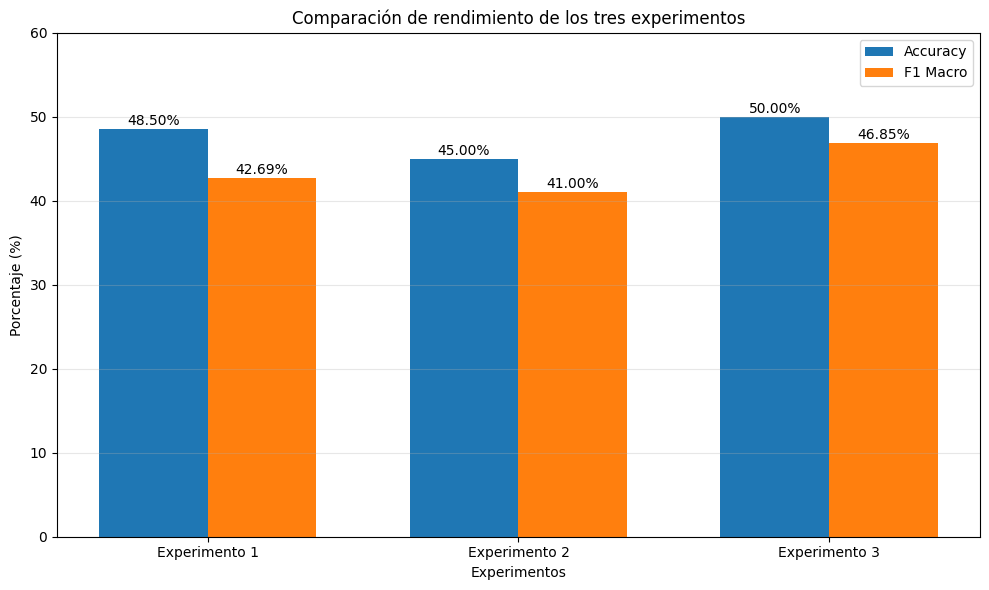

In [41]:
import matplotlib.pyplot as plt
import numpy as np

experimentos = ["Experimento 1", "Experimento 2", "Experimento 3"]

accuracy = [48.50, 45.00, 50.00]
f1_macro = [42.69, 41.00, 46.85]

x = np.arange(len(experimentos))
ancho = 0.35

plt.figure(figsize=(10, 6))

barras1 = plt.bar(
    x - ancho/2,
    accuracy,
    ancho,
    label="Accuracy"
)

barras2 = plt.bar(
    x + ancho/2,
    f1_macro,
    ancho,
    label="F1 Macro"
)

plt.title("Comparación de rendimiento de los tres experimentos")
plt.ylabel("Porcentaje (%)")
plt.xlabel("Experimentos")
plt.xticks(x, experimentos)
plt.ylim(0, 60)
plt.legend()
plt.grid(axis="y", alpha=0.3)

for barras in [barras1, barras2]:
    for barra in barras:
        altura = barra.get_height()
        plt.text(
            barra.get_x() + barra.get_width()/2,
            altura + 0.5,
            f"{altura:.2f}%",
            ha="center"
        )

plt.tight_layout()
plt.show()

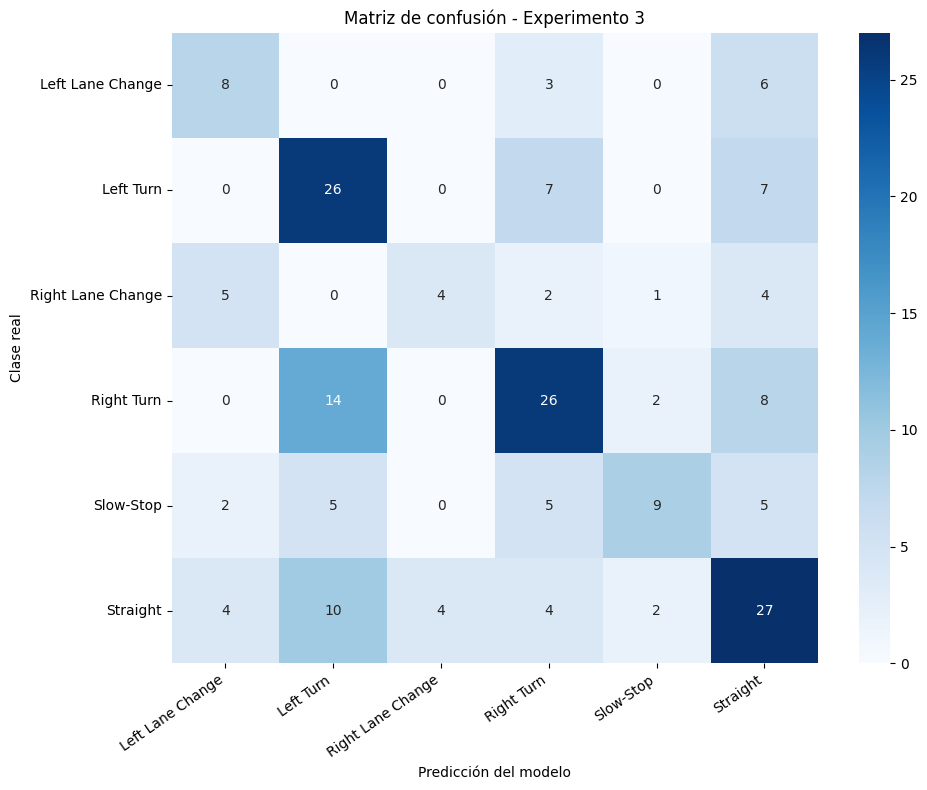

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

cm = confusion_matrix(y_real, y_pred)

nombres = [
    "Left Lane Change",
    "Left Turn",
    "Right Lane Change",
    "Right Turn",
    "Slow-Stop",
    "Straight"
]

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=nombres,
    yticklabels=nombres
)

plt.title("Matriz de confusión - Experimento 3")
plt.xlabel("Predicción del modelo")
plt.ylabel("Clase real")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()